# -*- coding: utf-8 -*-
"""
Created on Thu Oct  3 15:57:44 2024

@author: turinici
"""


"""
This program uses historical data in the format in : 
    https://turinici.com/wp-content/uploads/cours/common/close_cac40_historical.csv
    
It can also be downloaded form yahoo finance in daily
prices (at least the "close") if possible at lest 5 years
    
Idea: use yahoo e.g., yfinance package 
"pip install yfinance"


Then the code does : 
    
1'/ order by increasing date
    
2/ plot price histogram and returns  (with "log" and/or "actuarial")
    
3/ test normality of : prices, log returns, actuarial returns
    for instance can use scipy.stats.normaltest
    
4/ shows the random versus optimal results

TODO : replace "None" by what is required to implement the task.

"""

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from  scipy.stats import normaltest,kstest
#from scipy.special import softmax

# take csv from www course :we suppose it is available locally
data = pd.read_csv('close_cac40_historical.csv',sep=';', 
                   index_col = 'Date')

data.head()

,AI.PA,AIR.PA,ALO.PA,MT.AS,CS.PA,BNP.PA,EN.PA,CAP.PA,CA.PA,ACA.PA,...,STLA.PA,STM.PA,TEP.PA,HO.PA,TTE.PA,URW.AS,VIE.PA,DG.PA,VIV.PA,WLN.PA
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,18.313591,NaN,NaN,NaN,5.650104,16.165972,21.838985,163.247726,53.379601,NaN,...,NaN,NaN,16.062738,20.101891,11.044076,10.233084,NaN,5.191239,32.047607,NaN
2000-01-04,17.500856,NaN,NaN,NaN,5.442381,15.711578,20.757334,151.318329,50.005199,NaN,...,NaN,NaN,16.817142,19.954082,10.642475,10.404984,NaN,4.890053,30.504026,NaN
2000-01-05,17.338310,NaN,NaN,NaN,5.359290,15.379528,20.362444,136.390625,47.648937,NaN,...,NaN,NaN,16.147505,18.919428,10.374742,10.395162,NaN,5.001192,29.768993,NaN
2000-01-06,18.584503,NaN,NaN,NaN,5.317745,14.855226,19.572672,137.283737,46.834427,NaN,...,NaN,NaN,16.952768,19.605249,10.073537,10.707041,NaN,5.167898,29.419846,NaN
2000-01-07,18.356934,NaN,NaN,NaN,5.483925,15.047465,19.297972,144.173462,48.870708,NaN,...,NaN,NaN,17.207054,20.722685,10.123738,10.640738,NaN,5.334604,29.658733,NaN


In [2]:
# order by increasing date, keep variable 'data'
data = data.sort_index()

data.head()

,AI.PA,AIR.PA,ALO.PA,MT.AS,CS.PA,BNP.PA,EN.PA,CAP.PA,CA.PA,ACA.PA,...,STLA.PA,STM.PA,TEP.PA,HO.PA,TTE.PA,URW.AS,VIE.PA,DG.PA,VIV.PA,WLN.PA
Date,,,,,,,,,,,,,,,,,,,,,
1989-01-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


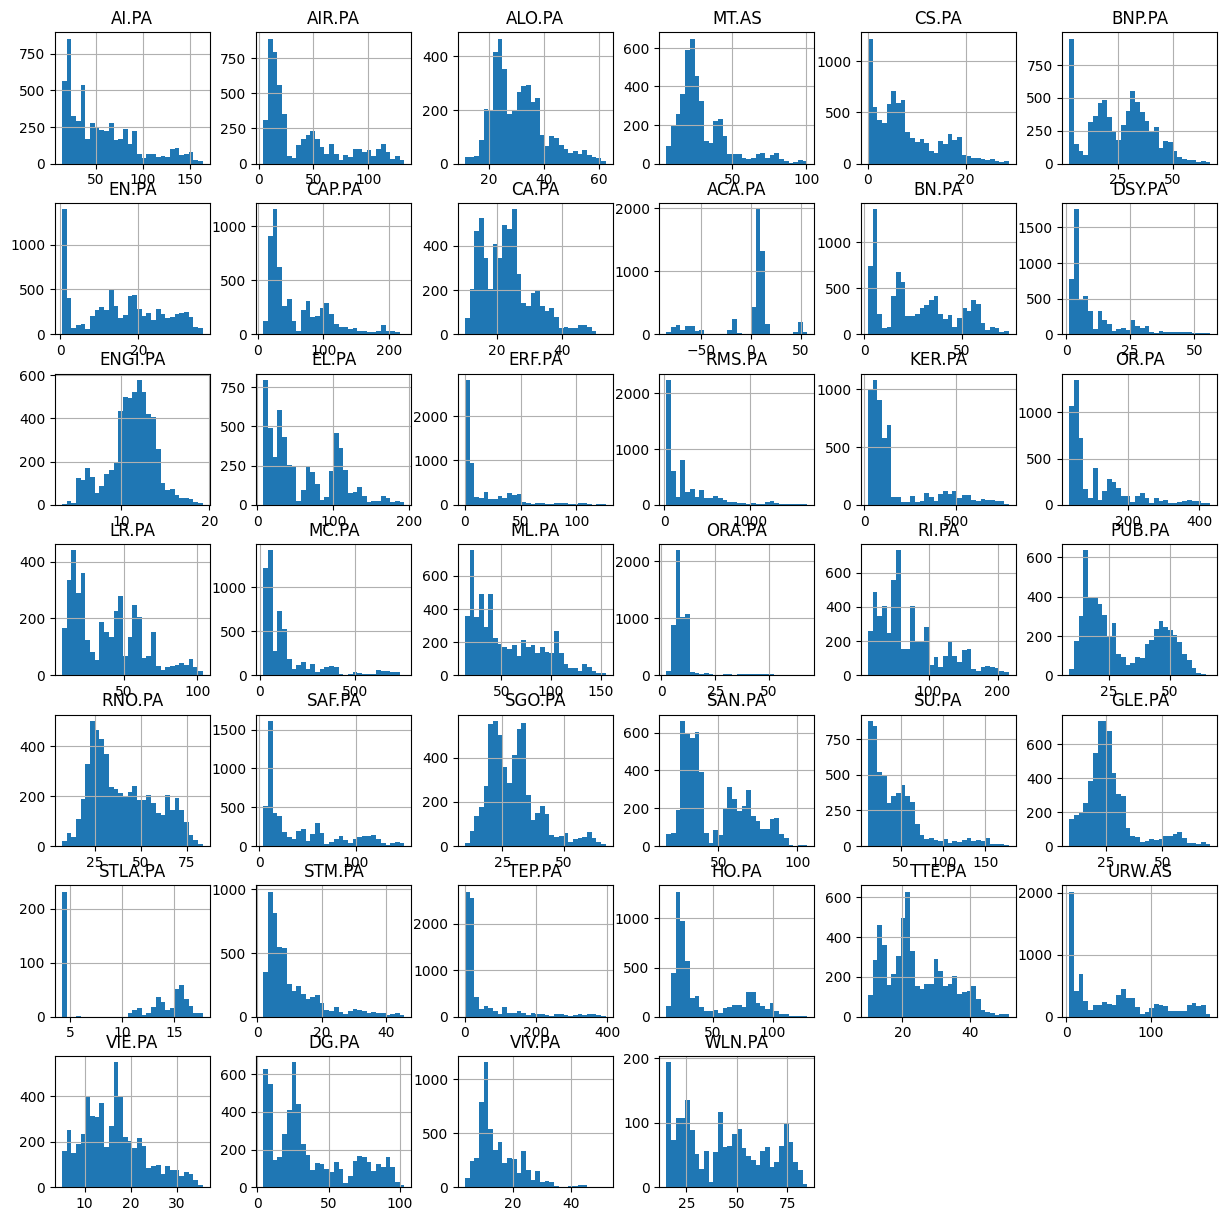

In [3]:
_ = data.hist(bins=30, figsize = (15,15))

C:\Users\Antonin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pandas\core\internals\blocks.py:393: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


array([[<Axes: title={'center': 'AI.PA'}>,
        <Axes: title={'center': 'AIR.PA'}>,
        <Axes: title={'center': 'ALO.PA'}>,
        <Axes: title={'center': 'MT.AS'}>,
        <Axes: title={'center': 'CS.PA'}>,
        <Axes: title={'center': 'BNP.PA'}>],
       [<Axes: title={'center': 'EN.PA'}>,
        <Axes: title={'center': 'CAP.PA'}>,
        <Axes: title={'center': 'CA.PA'}>,
        <Axes: title={'center': 'ACA.PA'}>,
        <Axes: title={'center': 'BN.PA'}>,
        <Axes: title={'center': 'DSY.PA'}>],
       [<Axes: title={'center': 'ENGI.PA'}>,
        <Axes: title={'center': 'EL.PA'}>,
        <Axes: title={'center': 'ERF.PA'}>,
        <Axes: title={'center': 'RMS.PA'}>,
        <Axes: title={'center': 'KER.PA'}>,
        <Axes: title={'center': 'OR.PA'}>],
       [<Axes: title={'center': 'LR.PA'}>,
        <Axes: title={'center': 'MC.PA'}>,
        <Axes: title={'center': 'ML.PA'}>,
        <Axes: title={'center': 'ORA.PA'}>,
        <Axes: title={'center': 'RI.PA'

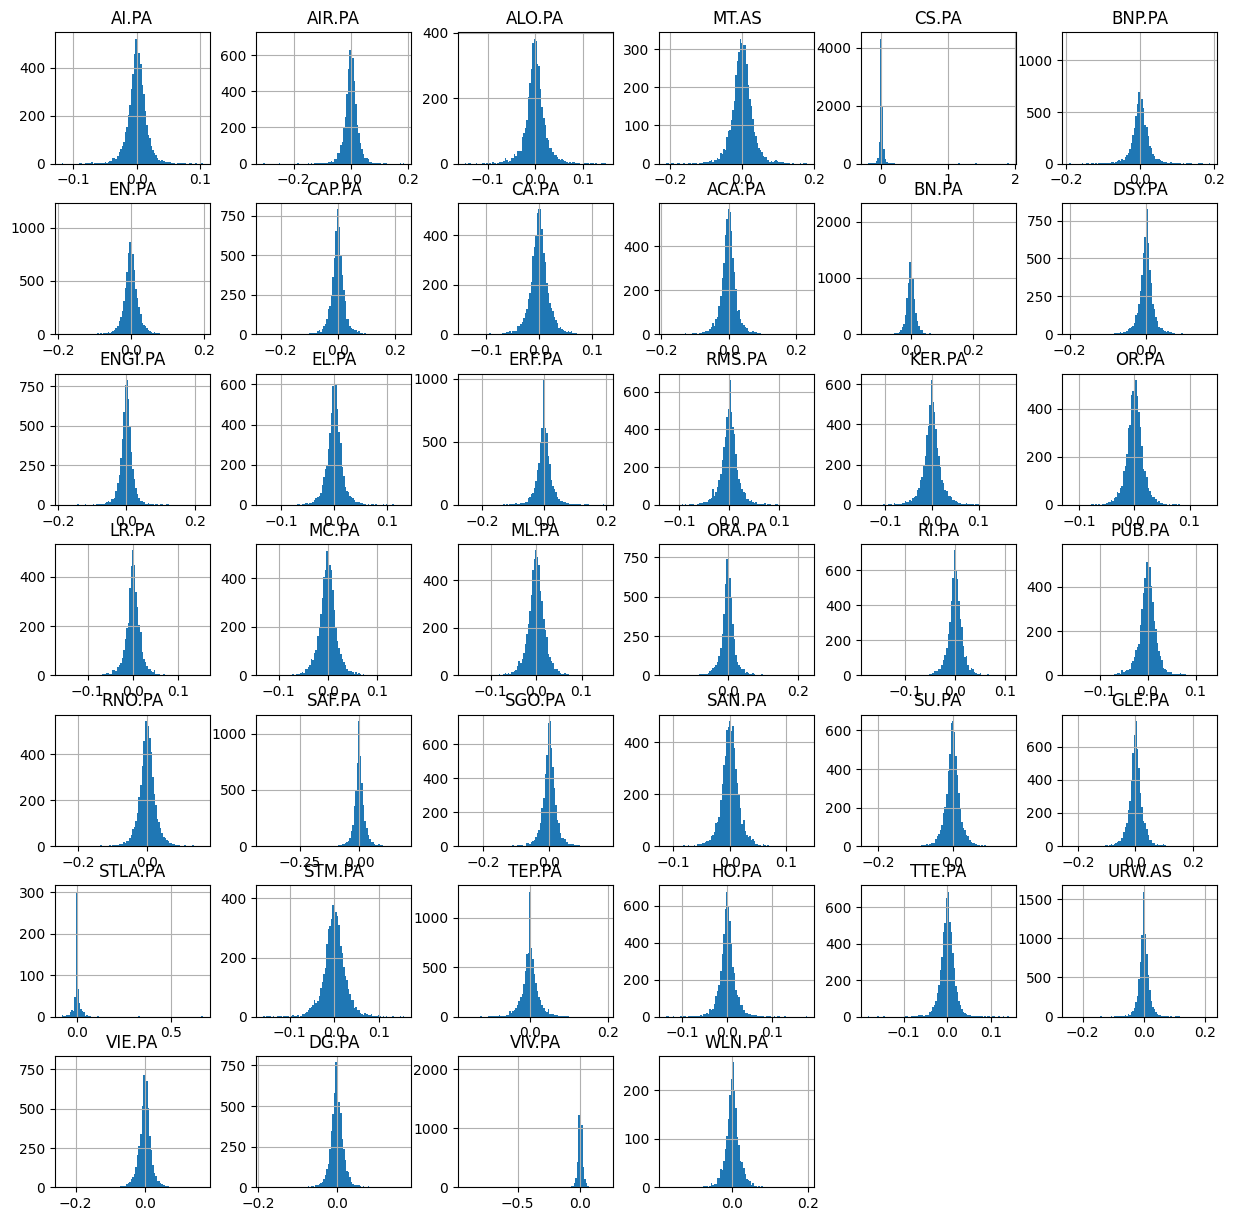

In [4]:
returns= np.log(data/data.shift(1))

returns.hist(bins=int(np.sqrt(returns.shape[0])), figsize = (15,15))

array([[<Axes: title={'center': 'AI.PA'}>,
        <Axes: title={'center': 'AIR.PA'}>,
        <Axes: title={'center': 'ALO.PA'}>,
        <Axes: title={'center': 'MT.AS'}>,
        <Axes: title={'center': 'CS.PA'}>,
        <Axes: title={'center': 'BNP.PA'}>],
       [<Axes: title={'center': 'EN.PA'}>,
        <Axes: title={'center': 'CAP.PA'}>,
        <Axes: title={'center': 'CA.PA'}>,
        <Axes: title={'center': 'ACA.PA'}>,
        <Axes: title={'center': 'BN.PA'}>,
        <Axes: title={'center': 'DSY.PA'}>],
       [<Axes: title={'center': 'ENGI.PA'}>,
        <Axes: title={'center': 'EL.PA'}>,
        <Axes: title={'center': 'ERF.PA'}>,
        <Axes: title={'center': 'RMS.PA'}>,
        <Axes: title={'center': 'KER.PA'}>,
        <Axes: title={'center': 'OR.PA'}>],
       [<Axes: title={'center': 'LR.PA'}>,
        <Axes: title={'center': 'MC.PA'}>,
        <Axes: title={'center': 'ML.PA'}>,
        <Axes: title={'center': 'ORA.PA'}>,
        <Axes: title={'center': 'RI.PA'

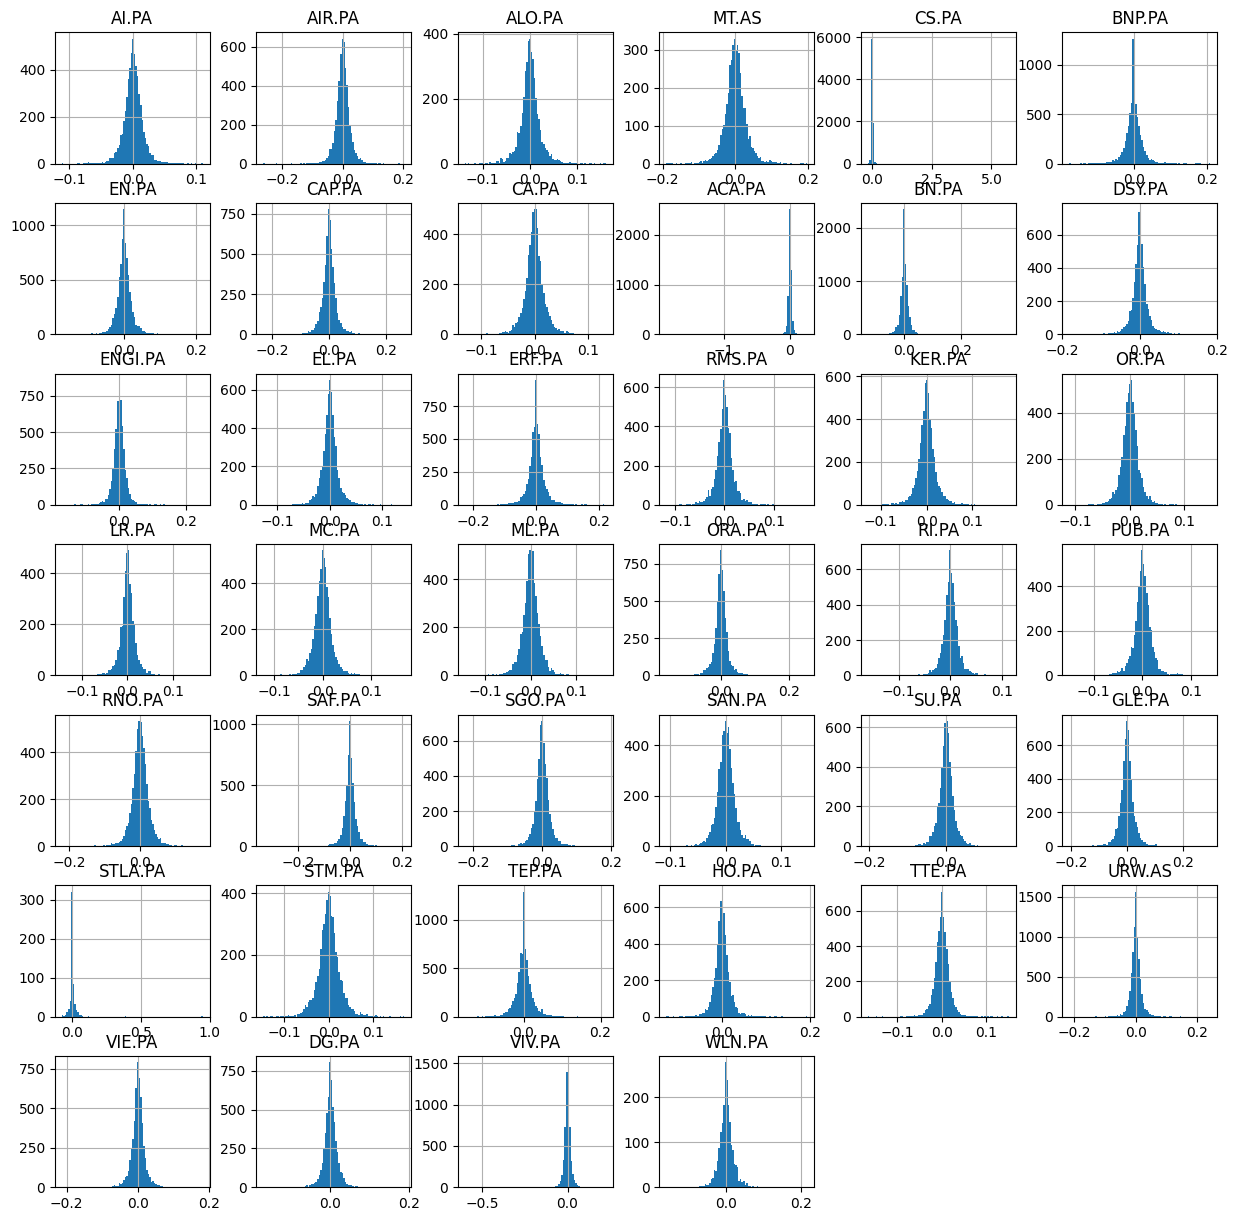

In [5]:
R= (data - data.shift(1))/data.shift(1)

R.hist(bins=int(np.sqrt(returns.shape[0])), figsize = (15,15))

In [6]:
def normality_test(data,kolmogorov_smirnov=False,level=0.01,print_results=True):
    """
    Tests normality of each column of dataframe "data". 
    Inputs:    
        kolmogorov_smirnov= false: use "normaltest", otherswise use kstest, both from scipy.stats
        level = p-value threshold level for the conclusions
        
    Outputs:  the number of yes/no in the results
    """

    pvalues=[]

    for cols in data.columns:
        # normality test 
        values = data[cols].dropna()

        if kolmogorov_smirnov:
            # put in pv the p-value of the Kolmogorov-Smirnov test
            pv = kstest(values, "norm").pvalue
        else:
            #  put in pv the p-value of the default scipy.stats normality test
            pv = normaltest(values).pvalue

        pvalues.append(pv)
        result = "not normal" if pv < level else "normal"
        print("Test pval=", pv, "res=", result)

    normalok = sum(pv >= level for pv in pvalues)
    normalnotok = sum(pv < level for pv in pvalues)

    if print_results:
        print("no. of normal =", normalok)
        print("no. of not normal =", normalnotok)

    return normalok, normalnotok


normality_test(returns)

Test pval= 1.1521122069721286e-134 res= not normal
Test pval= 1.4871484445370525e-264 res= not normal
Test pval= 1.9291767126632617e-114 res= not normal
Test pval= 7.589211521017387e-112 res= not normal
Test pval= 0.0 res= not normal
Test pval= 3.4502866284319348e-248 res= not normal
Test pval= 0.0 res= not normal
Test pval= 3.443926725130318e-179 res= not normal
Test pval= 6.046626375162701e-129 res= not normal
Test pval= 2.663983485096758e-167 res= not normal
Test pval= 0.0 res= not normal
Test pval= 1.483812360699637e-193 res= not normal
Test pval= 2.9155806598512715e-230 res= not normal
Test pval= 2.4128716032220203e-192 res= not normal
Test pval= 4.3687243702091375e-245 res= not normal
Test pval= 5.986670747739865e-157 res= not normal
Test pval= 1.2068242997918905e-153 res= not normal
Test pval= 7.590400597605357e-126 res= not normal
Test pval= 3.7786696110054304e-123 res= not normal
Test pval= 8.68080275482346e-140 res= not normal
Test pval= 3.6530348879363335e-131 res= not norma

(np.int64(0), np.int64(40))

Test pval= 0.025428757930302876 res= normal
Test pval= 0.01412845580561908 res= normal
Test pval= 0.28449279426465374 res= normal
Test pval= 0.2807546954064228 res= normal
Test pval= 0.009428521835360283 res= not normal
Test pval= 0.14982216104037124 res= normal
Test pval= 0.07490385366598308 res= normal
Test pval= 0.16934912108574976 res= normal
Test pval= 0.006228354120572415 res= not normal
Test pval= 0.00386017121115986 res= not normal
Test pval= 0.00014234445964435234 res= not normal
Test pval= 0.15592449975168216 res= normal
Test pval= 5.4492134141853295e-12 res= not normal
Test pval= 0.027428045061480538 res= normal
Test pval= 0.00011538203750856842 res= not normal
Test pval= 0.07350032657006558 res= normal
Test pval= 0.10474460687572516 res= normal
Test pval= 0.0015506993297125186 res= not normal
Test pval= 0.36679129167153646 res= normal
Test pval= 0.011263558096640853 res= normal
Test pval= 1.4403372640862257e-05 res= not normal
Test pval= 0.017985610179734424 res= normal
Tes

(np.int64(31), np.int64(9))

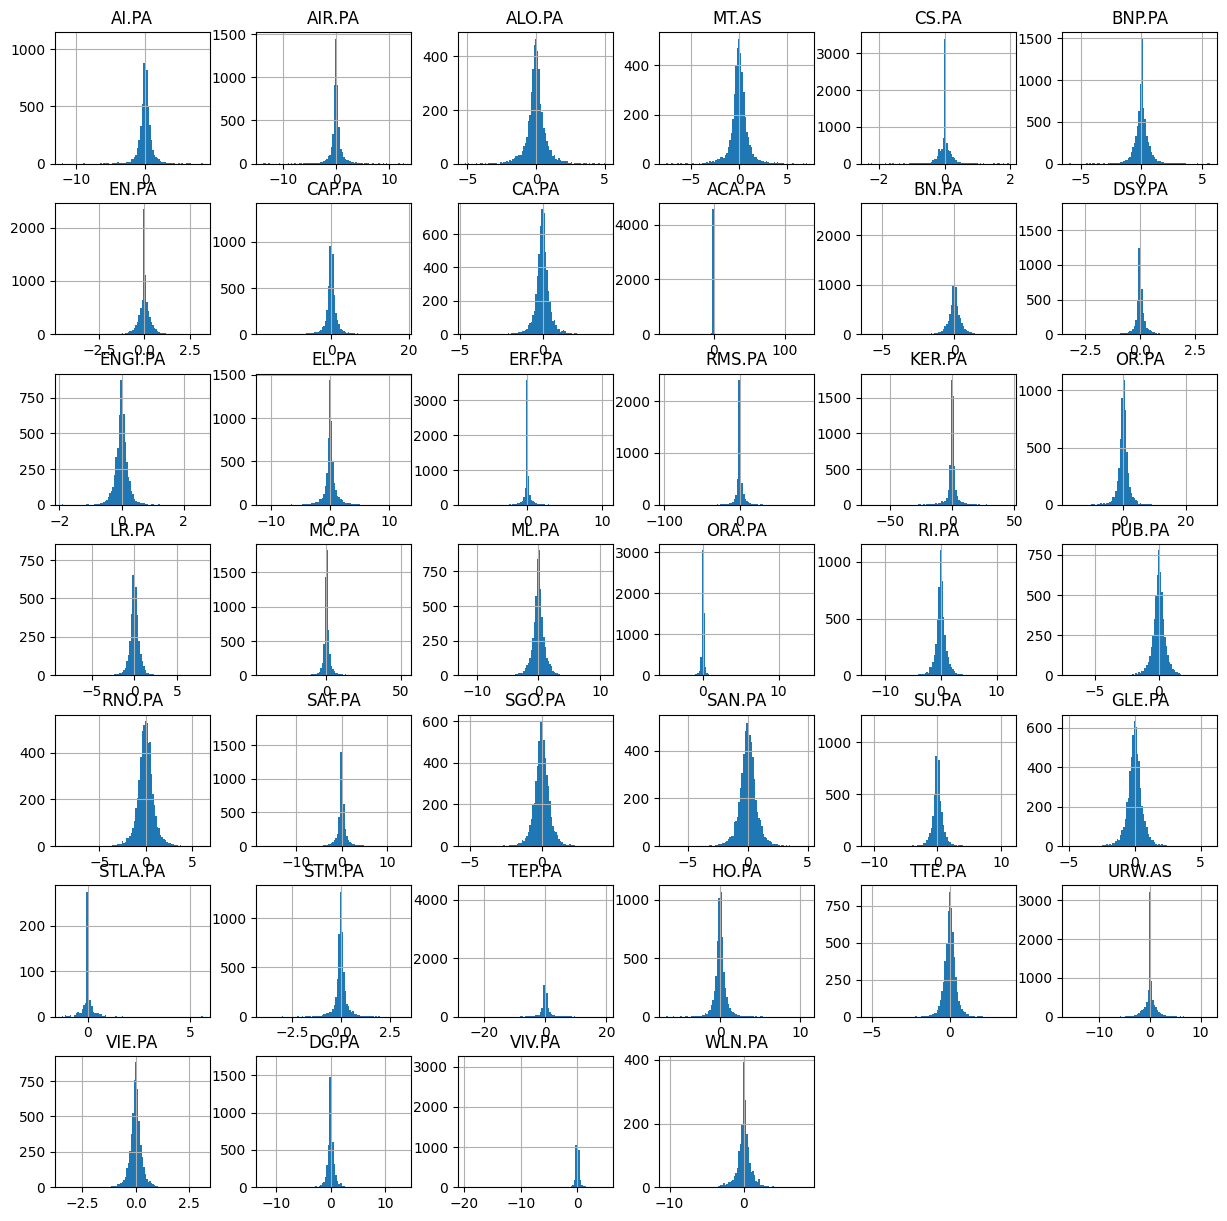

In [7]:
normality_test(returns.tail(25*3))#test last 3 months

###########################################################
print('normality tests for increments, not returns!!')
increments= data-data.shift(1)
_=increments.hist(bins=int(np.sqrt(increments.shape[0])), figsize = (15,15))

normality_test(increments.tail(25*3))
########################################################################

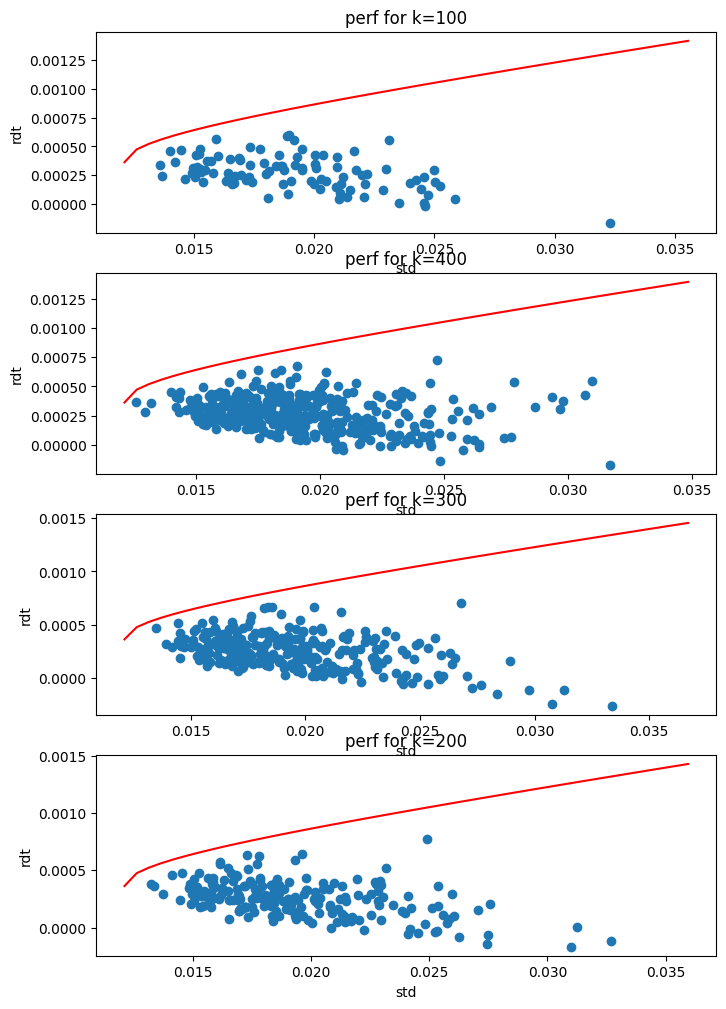

In [27]:
nb=10  #will work with nb stocks
all_returns=returns.copy()#backup
nb_all=all_returns.shape[1]
if(nb>nb_all):
    print("too many number of stocks, revert to max")
    nb=nb_all
#choose the stock names
nb_stocks_names=np.random.choice(all_returns.keys(),nb,replace=False)
returns_small=all_returns.loc[:,nb_stocks_names]

fig, axs = plt.subplots(4,1,figsize=(8,12))

for k in [100,200,300,400]:
    #compute avg and cov of returns
    mean_returns=returns_small.mean()
    cov_matrix= returns_small.cov()
    rdt_list=[]
    std_list=[]
    for _ in range(k):
        #sample at random some "allocation"
        allocation = 3*np.random.dirichlet(np.ones(nb)) - 2/nb
        rdt_port = allocation@mean_returns
        std_port = np.sqrt(allocation@cov_matrix@allocation)
        rdt_list.append(rdt_port)
        std_list.append(std_port)

    inverse_cov = np.linalg.inv(cov_matrix)
    # constants of the efficient frontier
    onesM = np.ones(nb)
    a = onesM @ inverse_cov @ onesM
    b = onesM @ inverse_cov @ mean_returns

    # minimum-variance portfolio standard deviation
    sigmarange= np.linspace(1./np.sqrt(a)+1.e-10, 1.1*np.max(std_list),47)

    # efficient frontier: sqrt argument is non-negative by construction
    factor = np.sqrt((mean_returns - b/a) @ inverse_cov @ (mean_returns - b/a))
    optimal_return = b/a + np.sqrt(sigmarange**2 - 1./a)*factor

    axs[1 - k//100].scatter(std_list,rdt_list)
    axs[1 - k//100].plot(sigmarange,optimal_return,'r-')                                                   
    axs[1 - k//100].set_xlabel('std')
    axs[1 - k//100].set_ylabel('rdt')
    axs[1 - k//100].set_title('perf for k='+str(k))

In [107]:
def market_portfolio(R,t, T, r0 = 0, input_portf = None):
    r = R.iloc[t:T]
    mu, S = r.mean().values, r.cov().values
    try:
        inv_S = np.linalg.pinv(S)
    except:
        inv_S = np.eye(r.shape[1])
    W = inv_S @ (mu - r0)
    W /= (1e-10 + W.sum())
    portf = W if input_portf is None else input_portf
    perf = (1 + r.values @ portf).prod() - 1
    return W,perf

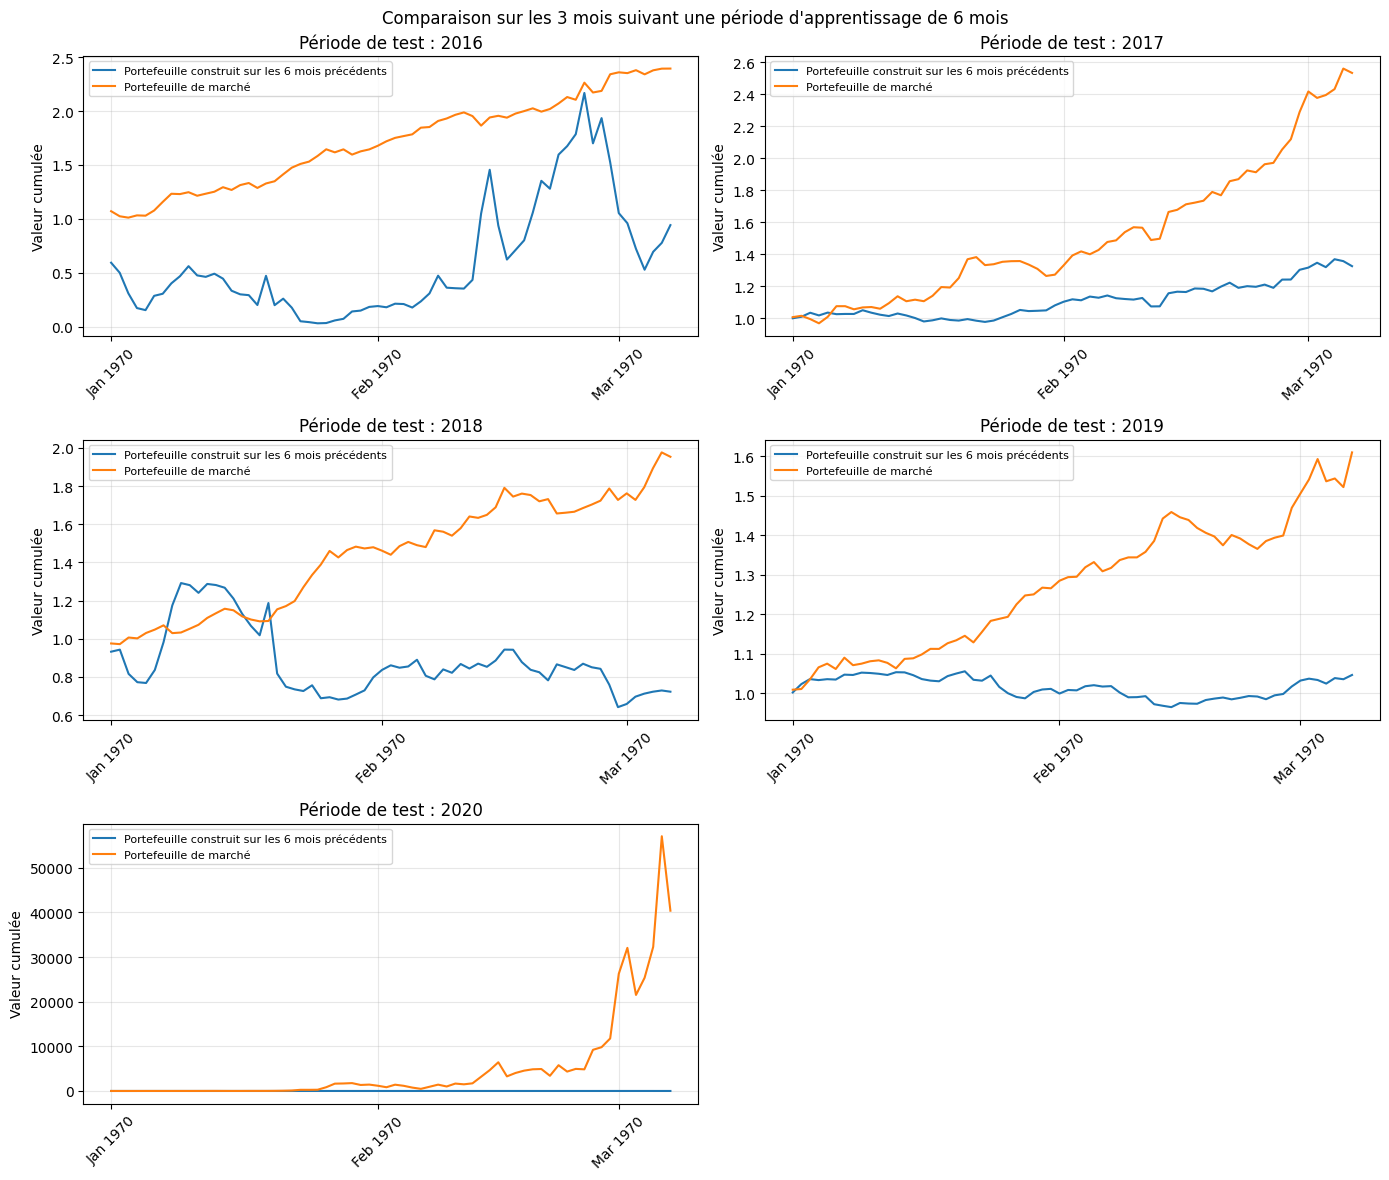

In [ ]:
import matplotlib.dates as mdates

nb = min(15, returns.shape[1])
returns_small = (
    returns.iloc[:, :nb]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
    .astype(float)
)
returns_small.index = pd.to_datetime(returns_small.index)
returns_small = returns_small.sort_index()
dates = returns_small.index
first_date = pd.Timestamp("2015-01-01")

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.ravel()

for ax, year in zip(axes, range(1, 6)):
    start = first_date + pd.DateOffset(years=year)
    train_start = dates.searchsorted(start)
    test_start = dates.searchsorted(start + pd.DateOffset(months=6))
    test_end = dates.searchsorted(start + pd.DateOffset(months=9))

    if test_start >= test_end:
        ax.set_visible(False)
        continue

    weights_past, _ = market_portfolio(returns_small, train_start, test_start)
    weights_market, _ = market_portfolio(returns_small, test_start, test_end)
    test_returns = returns_small.iloc[test_start:test_end]

    portfolio_value = np.exp(np.cumsum(test_returns.values @ weights_past))
    market_value = np.exp(np.cumsum(test_returns.values @ weights_market))

    ax.plot(
        test_returns.index,
        portfolio_value,
        label="Portefeuille construit sur les 6 mois précédents"
    )
    ax.plot(test_returns.index, market_value, label="Portefeuille de marché")
    ax.set_title(f"Période de test : {start.year}")
    ax.set_ylabel("Valeur cumulée")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)

axes[-1].set_visible(False)
fig.suptitle("Comparaison sur les 3 mois suivant une période d'apprentissage de 6 mois")
fig.tight_layout()
plt.show()